# 03 - Modelos (entregable parcial)

En este notebook empezamos la **comparación de modelos de clasificación** sobre el dataset que dejamos listo en el preprocesamiento (`data/processed/dataset_proveedor_corte.csv`): una fila por proveedor y fecha de corte, con `target = 1` si el proveedor recibe una sanción (inhabilitación o multa) en los **12 meses siguientes** al corte.

**Alcance de esta entrega (parcial):**
- Listamos los **cuatro modelos** que vamos a comparar y la literatura en la que se apoyan (sección 6).
- Implementamos y evaluamos el **baseline: regresión logística**, y un segundo modelo: el **árbol de decisión**.
- **KNN** y **MLP** quedan propuestos para el entregable final, con la misma metodología.

**Decisiones principales:**

| Tema | Qué hacemos | Por qué |
|---|---|---|
| División de los datos | **Por tiempo**: entrenamos con los cortes más antiguos, ajustamos con uno intermedio y probamos con el más reciente | Así simulamos predecir el futuro y no mezclamos información de después |
| Preprocesamiento | Recorte de valores extremos, imputación con la mediana (+ indicador de nulo) y estandarización, **todo ajustado solo con train** | Evitamos filtrar información de validación y prueba |
| Desbalance de clases | Pesos de clase (`class_weight`) y un **umbral de decisión** elegido en validación | Hay muy pocos proveedores sancionados (menos del 4%) |
| Métrica principal | **PR-AUC**, apoyada en recall, precision, F1 y ROC-AUC | Con clases tan desbalanceadas, el accuracy engaña |
| Selección de hiperparámetros | Probamos pocos valores y elegimos el mejor en **validación** | Dejamos prueba para evaluar una sola vez al final |

**Secciones:**
1. Preparación
2. Carga de datos
3. División temporal (train / validación / prueba)
4. Variables y preprocesamiento detallado
5. Métricas y funciones de apoyo
6. Propuesta de modelos
7. Regresión logística (baseline)
8. Árbol de decisión
9. Comparación en prueba
10. Qué variables pesan y qué casos detectamos
11. Guardar resultados
12. Conclusiones y próximos pasos

## 1. Preparación

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss,
    precision_score, recall_score, f1_score,
    confusion_matrix, precision_recall_curve, roc_curve,
)

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", "{:,.3f}".format)

SEED = 42
np.random.seed(SEED)

# Paleta de colores (la misma idea que en los tutoriales del curso)
color_primary = "#1f77b4"
color_secondary = "#ff7f0e"
color_accent1 = "#2E86AB"
color_accent2 = "#A23B72"
COLORES = {"Regresión logística": color_accent1, "Árbol de decisión": color_accent2}


def mostrar(texto):
    display(Markdown(texto))

In [2]:
def localizar_raiz_repo():
    # Funciona si el notebook está en proyecto/ o en proyecto/notebooks/
    cwd = Path.cwd().resolve()
    for carpeta in [cwd, *cwd.parents]:
        if (carpeta / "data" / "processed").is_dir():
            return carpeta
    raise FileNotFoundError(
        "No se encontró data/processed. Abre el notebook desde dentro del repositorio. "
        f"Directorio actual: {cwd}"
    )


ROOT = localizar_raiz_repo()
PROCESSED = ROOT / "data" / "processed"
RESULTS = ROOT / "results"
PLOTS = RESULTS / "plots"
PLOTS.mkdir(parents=True, exist_ok=True)


def guardar_grafico(nombre):
    # Guarda la figura actual en results/plots/ antes de mostrarla
    plt.savefig(PLOTS / nombre, dpi=150, bbox_inches="tight")


print("Raíz del repositorio:", ROOT)
print("Datos procesados:    ", PROCESSED)
print("Resultados:          ", RESULTS)
print("pandas:", pd.__version__)

Raíz del repositorio: D:\CDX\Workspace\G5-IA-APLICADA
Datos procesados:     D:\CDX\Workspace\G5-IA-APLICADA\data\processed
Resultados:           D:\CDX\Workspace\G5-IA-APLICADA\results
pandas: 3.0.6


## 2. Carga de datos

Leemos el archivo que generamos en `02_preprocesamiento.ipynb`. Recordemos que **cada fila es un proveedor en una fecha de corte** (30 de junio o 31 de diciembre), que las predictoras usan solo información hasta esa fecha y que el `target` mira los 12 meses siguientes.

In [3]:
df = pd.read_csv(PROCESSED / "dataset_proveedor_corte.csv",
                 parse_dates=["fecha_corte"], dtype={"id_proveedor": "string"})
print(f"Filas: {len(df):,} | Columnas: {df.shape[1]} | Proveedores distintos: {df['id_proveedor'].nunique():,}")

resumen_cortes = df.groupby("fecha_corte")["target"].agg(filas="size", positivos="sum", prevalencia="mean")
resumen_cortes["prevalencia_%"] = (resumen_cortes.pop("prevalencia") * 100).round(2)
resumen_cortes

Filas: 30,049 | Columnas: 49 | Proveedores distintos: 10,033


,filas,positivos,prevalencia_%
fecha_corte,,,
2023-06-30,1318,33,2.500
2023-12-31,4144,96,2.320
2024-06-30,6148,112,1.820
2024-12-31,8406,208,2.470
2025-06-30,10033,351,3.500


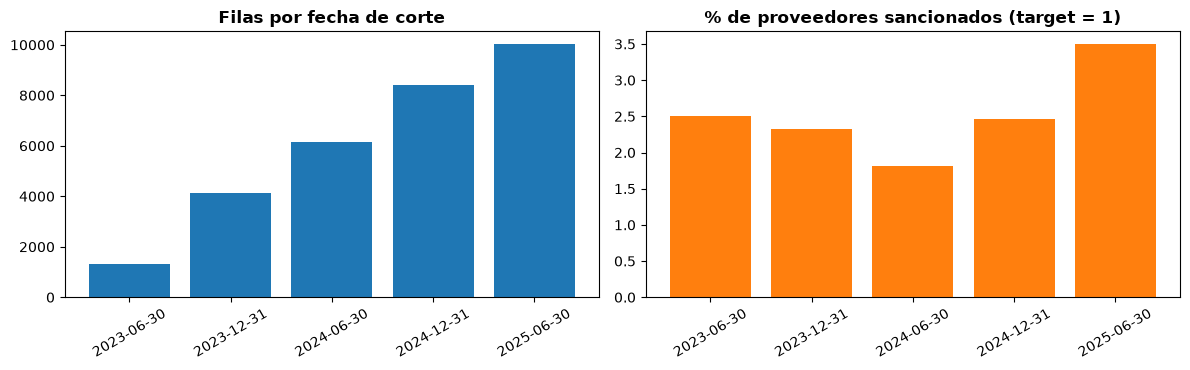


**Qué vimos:**
- El dataset tiene **30,049 filas** de **10,033 proveedores**; un mismo proveedor puede aparecer en varios cortes.
- Cada corte tiene más filas que el anterior (de 1,318 a 10,033), porque con el tiempo se acumulan más proveedores con historial.
- La clase positiva es **rara**: entre 1.82% y 3.50% de las filas. Un modelo que diga siempre "no sancionado" tendría un accuracy altísimo y no serviría de nada.


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
etiquetas = resumen_cortes.index.strftime("%Y-%m-%d")

ax[0].bar(etiquetas, resumen_cortes["filas"], color=color_primary)
ax[0].set_title("Filas por fecha de corte", fontsize=12, fontweight="bold")
ax[0].tick_params(axis="x", rotation=30)

ax[1].bar(etiquetas, resumen_cortes["prevalencia_%"], color=color_secondary)
ax[1].set_title("% de proveedores sancionados (target = 1)", fontsize=12, fontweight="bold")
ax[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
guardar_grafico("00_cortes.png")
plt.show()

mostrar(f"""
**Qué vimos:**
- El dataset tiene **{len(df):,} filas** de **{df['id_proveedor'].nunique():,} proveedores**; un mismo proveedor puede aparecer en varios cortes.
- Cada corte tiene más filas que el anterior (de {resumen_cortes['filas'].iloc[0]:,} a {resumen_cortes['filas'].iloc[-1]:,}), porque con el tiempo se acumulan más proveedores con historial.
- La clase positiva es **rara**: entre {resumen_cortes['prevalencia_%'].min():.2f}% y {resumen_cortes['prevalencia_%'].max():.2f}% de las filas. Un modelo que diga siempre "no sancionado" tendría un accuracy altísimo y no serviría de nada.
""")

## 3. División temporal (train / validación / prueba)

No usamos una partición aleatoria: los cortes más recientes se quedan fuera del entrenamiento para simular una predicción real hacia el futuro.

| Conjunto | Cortes | Para qué lo usamos |
|---|---|---|
| **Entrenamiento** | 2023-06-30, 2023-12-31, 2024-06-30 | Ajustar los modelos |
| **Validación** | 2024-12-31 | Elegir hiperparámetros y el umbral de decisión |
| **Prueba** | 2025-06-30 | Evaluar una sola vez al final |

In [5]:
FIN_TRAIN = pd.Timestamp("2024-06-30")
CORTE_VAL = pd.Timestamp("2024-12-31")
CORTE_TEST = pd.Timestamp("2025-06-30")

train = df[df["fecha_corte"] <= FIN_TRAIN].copy()
val = df[df["fecha_corte"] == CORTE_VAL].copy()
test = df[df["fecha_corte"] == CORTE_TEST].copy()

assert len(train) > 0 and len(val) > 0 and len(test) > 0, "Algún conjunto quedó vacío: revisar las fechas de corte"
assert len(train) + len(val) + len(test) == len(df), "Hay cortes que no entran en ningún conjunto"

partes = {"Entrenamiento": train, "Validación": val, "Prueba": test}
tabla_split = pd.DataFrame({
    "Conjunto": list(partes),
    "Cortes": [", ".join(sorted(d.strftime("%Y-%m-%d") for d in p["fecha_corte"].unique())) for p in partes.values()],
    "Filas": [len(p) for p in partes.values()],
    "Positivos": [int(p["target"].sum()) for p in partes.values()],
    "Prevalencia %": [round(p["target"].mean() * 100, 2) for p in partes.values()],
})
display(tabla_split)

en_train = test["id_proveedor"].isin(set(train["id_proveedor"])).mean() * 100
mostrar(f"""
**Qué vimos:**
- Entrenamos con **{len(train):,} filas** ({int(train['target'].sum())} positivos), validamos con {len(val):,} y probamos con {len(test):,} ({int(test['target'].sum())} positivos).
- La prevalencia de prueba ({test['target'].mean()*100:.2f}%) es la referencia del **azar**: un modelo sin información tendría un PR-AUC cercano a ese valor.
- El **{en_train:.0f}%** de las filas de prueba corresponde a proveedores que ya aparecían en entrenamiento (en un corte anterior). Es normal en este problema, pero hay que tenerlo en cuenta al interpretar los resultados.
""")

,Conjunto,Cortes,Filas,Positivos,Prevalencia %
0,Entrenamiento,"2023-06-30, 2023-12-31, 2024-06-30",11610,241,2.080
1,Validación,2024-12-31,8406,208,2.470
2,Prueba,2025-06-30,10033,351,3.500



**Qué vimos:**
- Entrenamos con **11,610 filas** (241 positivos), validamos con 8,406 y probamos con 10,033 (351 positivos).
- La prevalencia de prueba (3.50%) es la referencia del **azar**: un modelo sin información tendría un PR-AUC cercano a ese valor.
- El **61%** de las filas de prueba corresponde a proveedores que ya aparecían en entrenamiento (en un corte anterior). Es normal en este problema, pero hay que tenerlo en cuenta al interpretar los resultados.


## 4. Variables y preprocesamiento detallado

Separamos las columnas según el diccionario del notebook anterior:
- **Identificación** (`id_proveedor`, `fecha_corte`): solo sirven para ubicar la fila, no entran al modelo.
- **Target** (`target`): lo que queremos predecir.
- **`y_inhabilitacion_12m` y `y_multa_12m`**: son partes del target, así que las **sacamos** de las predictoras (si no, el modelo "haría trampa").
- **Predictoras**: las 44 variables restantes.

In [6]:
COL_ID = ["id_proveedor", "fecha_corte"]
COL_TARGET = "target"
COL_FUGA = ["y_inhabilitacion_12m", "y_multa_12m"]
FEATURES = [c for c in df.columns if c not in COL_ID + [COL_TARGET] + COL_FUGA]
assert len(FEATURES) == 44, f"Se esperaban 44 predictoras y hay {len(FEATURES)}"

X_train, y_train = train[FEATURES], train[COL_TARGET].values
X_val, y_val = val[FEATURES], val[COL_TARGET].values
X_test, y_test = test[FEATURES], test[COL_TARGET].values

print(f"Predictoras: {len(FEATURES)}")
nulos_train = (X_train.isna().mean() * 100).round(1).rename("%_nulos_train")
nulos_train[nulos_train > 0].sort_values(ascending=False).to_frame()

Predictoras: 44


,%_nulos_train
crec_n_12m,100.000
crec_monto_12m,100.000
dias_desde_ultima_sancion,95.600
log_monto_pen_hist_std,79.800
dias_prom_entre_contratos,79.700
crec_n_6m,73.400
crec_monto_6m,73.400
dias_conv_a_firma_medio,0.500
log_monto_pen_hist_max,0.400
log_monto_pen_hist_mediana,0.400


Los nulos que quedan **tienen sentido** y no son errores: por ejemplo, `crec_*` es nulo cuando el proveedor no tenía contratos en el periodo anterior, y `dias_desde_ultima_sancion` es nulo cuando nunca tuvo una sanción. Por eso, en vez de solo rellenarlos, también le agregamos al modelo una columna que indica "este dato estaba vacío".

**Pasos del preprocesamiento** (siempre ajustados **solo con train** y aplicados igual a validación y prueba, usando `Pipeline`):
1. **Recorte de extremos (winsorización):** en las variables con colas muy largas (crecimientos, razones, días y número de contratos) limitamos los valores al rango entre el percentil 1 y el 99 de train. No lo hacemos en las variables que casi siempre valen 0 (por ejemplo, las sanciones previas), porque el recorte borraría su información.
2. **Imputación con la mediana** + columna indicadora de nulo.
3. **Estandarización** (media 0, desviación 1): la necesita la regresión logística (y la necesitarán KNN y el MLP en el entregable final). El árbol no la necesita (trabaja con divisiones, no con distancias).

In [7]:
class Winsorizador(BaseEstimator, TransformerMixin):
    """Recorta las columnas indicadas a los percentiles aprendidos en train."""

    def __init__(self, columnas, q_bajo=0.01, q_alto=0.99):
        self.columnas = columnas
        self.q_bajo = q_bajo
        self.q_alto = q_alto

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.limites_ = {c: (X[c].quantile(self.q_bajo), X[c].quantile(self.q_alto))
                         for c in self.columnas}
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        for c, (bajo, alto) in self.limites_.items():
            X[c] = X[c].clip(bajo, alto)
        return X


# Variables con colas largas (no incluimos las que casi siempre valen 0)
COLS_EXTREMOS = [
    "crec_n_6m", "crec_monto_6m", "crec_n_12m", "crec_monto_12m",
    "ratio_contratado_ref_medio", "dias_conv_a_firma_medio", "duracion_contrato_dias_medio",
    "dias_prom_entre_contratos", "n_contratos_hist",
]
assert set(COLS_EXTREMOS) <= set(FEATURES)


def armar_preprocesador(escalar=True):
    pasos = [("extremos", Winsorizador(COLS_EXTREMOS)),
             ("imputador", SimpleImputer(strategy="median", add_indicator=True))]
    if escalar:
        pasos.append(("escalador", StandardScaler()))
    return Pipeline(pasos)


def armar_pipeline(modelo, escalar=True):
    return Pipeline([("prep", armar_preprocesador(escalar)), ("modelo", modelo)])


n_neg, n_pos = int((y_train == 0).sum()), int((y_train == 1).sum())
print(f"Train: {n_neg:,} negativos y {n_pos:,} positivos (los positivos son el {n_pos / len(y_train) * 100:.1f}%)")

Train: 11,369 negativos y 241 positivos (los positivos son el 2.1%)


### Primer vistazo: ¿las sanciones previas ayudan?

Antes de modelar, miramos qué tan frecuente es el target según tres variables binarias (solo con datos de train). Si la tasa cambia mucho entre 0 y 1, esa variable le dará información al modelo.

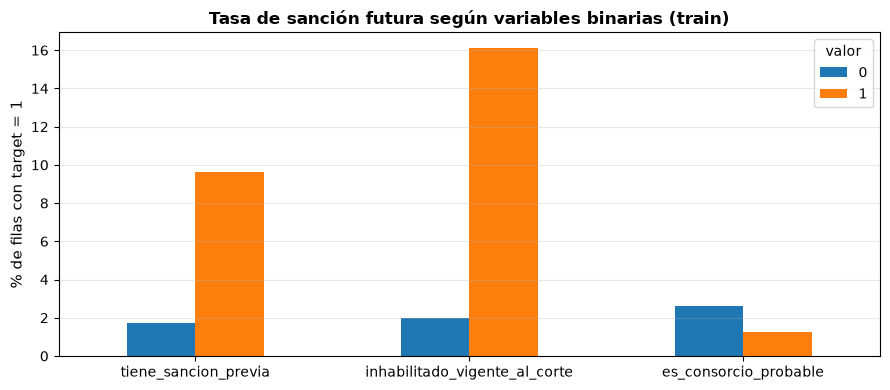


**Qué vimos:**
- Entre quienes **no** tenían sanciones previas, el 1.73% fue sancionado al año siguiente; entre quienes **sí** tenían, el **9.61%**.
- Con una inhabilitación vigente al corte la tasa es 16.13% (sin ella, 2.00%).
- Los consorcios probables tienen una tasa de 1.26% frente a 2.60% del resto.


In [8]:
binarias = ["tiene_sancion_previa", "inhabilitado_vigente_al_corte", "es_consorcio_probable"]
filas = []
for c in binarias:
    for v in (0, 1):
        sub = train[train[c] == v]
        filas.append({"variable": c, "valor": v, "filas": len(sub),
                      "tasa_%": sub["target"].mean() * 100 if len(sub) else np.nan})
tabla_bin = pd.DataFrame(filas)

pivote = tabla_bin.pivot(index="variable", columns="valor", values="tasa_%").loc[binarias]
fig, ax = plt.subplots(figsize=(9, 4))
pivote.plot.bar(ax=ax, color=[color_primary, color_secondary], rot=0)
ax.set_ylabel("% de filas con target = 1", fontsize=11)
ax.set_xlabel("")
ax.set_title("Tasa de sanción futura según variables binarias (train)", fontsize=12, fontweight="bold")
ax.legend(title="valor")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
guardar_grafico("01_tasa_por_binaria.png")
plt.show()

t = tabla_bin.set_index(["variable", "valor"])["tasa_%"]
mostrar(f"""
**Qué vimos:**
- Entre quienes **no** tenían sanciones previas, el {t[('tiene_sancion_previa', 0)]:.2f}% fue sancionado al año siguiente; entre quienes **sí** tenían, el **{t[('tiene_sancion_previa', 1)]:.2f}%**.
- Con una inhabilitación vigente al corte la tasa es {t[('inhabilitado_vigente_al_corte', 1)]:.2f}% (sin ella, {t[('inhabilitado_vigente_al_corte', 0)]:.2f}%).
- Los consorcios probables tienen una tasa de {t[('es_consorcio_probable', 1)]:.2f}% frente a {t[('es_consorcio_probable', 0)]:.2f}% del resto.
""")

## 5. Métricas y funciones de apoyo

Como la clase positiva es rara, usamos estas métricas (todas sobre la clase "sancionado"):

- **PR-AUC:** área bajo la curva precision-recall. Es nuestra **métrica principal**; su valor "al azar" es la prevalencia (menos del 4%), así que se interpreta contra ese número.
- **ROC-AUC:** qué tan bien ordena el modelo a los proveedores (0.5 = azar, 1 = perfecto). Complemento general.
- **Precision:** de las alertas que emitimos, cuántas eran realmente sancionados.
- **Recall:** de los sancionados reales, cuántos detectamos.
- **F1:** equilibrio entre precision y recall.
- **Recall en el top 10%:** si solo revisáramos al 10% de proveedores con mayor riesgo, qué proporción de los sancionados atraparíamos. Es la métrica más cercana al uso real (priorizar revisiones).
- **Brier:** error de las probabilidades (más bajo es mejor). Ojo: como usamos pesos de clase, las probabilidades salen infladas y este valor **no se puede leer como calibración**; lo reportamos solo como referencia.

**Umbral de decisión:** Precision, Recall y F1 dependen de a partir de qué probabilidad damos la alerta. Para cada modelo elegimos el umbral que maximiza el F1 en **validación** y lo usamos tal cual en prueba.

In [9]:
def mejor_umbral(y, proba):
    # Umbral que maximiza el F1 (se calcula solo con validación)
    p, r, t = precision_recall_curve(y, proba)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return float(t[np.argmax(f1)])


def recall_top(y, proba, fraccion=0.10):
    k = max(1, int(round(fraccion * len(y))))
    top = np.argsort(-proba)[:k]
    return y[top].sum() / y.sum() if y.sum() > 0 else np.nan


def evaluar(y, proba, umbral):
    pred = (proba >= umbral).astype(int)
    return {
        "PR-AUC": average_precision_score(y, proba),
        "ROC-AUC": roc_auc_score(y, proba),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "Recall top 10%": recall_top(y, proba),
        "Brier": brier_score_loss(y, proba),
    }


def ajustar_y_comparar(valores, construir, escalar=True):
    """Entrena un pipeline por cada valor del hiperparámetro y mide PR-AUC en train y validación."""
    filas, pipes = [], {}
    for v in valores:
        pipe = armar_pipeline(construir(v), escalar)
        pipe.fit(X_train, y_train)
        pipes[v] = pipe
        filas.append({"valor": v,
                      "PR-AUC train": average_precision_score(y_train, pipe.predict_proba(X_train)[:, 1]),
                      "PR-AUC val": average_precision_score(y_val, pipe.predict_proba(X_val)[:, 1])})
    return pd.DataFrame(filas), pipes


def graficar_tuning(tabla, titulo, etiqueta_x, nombre_archivo):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    x = np.arange(len(tabla))
    ax.plot(x, tabla["PR-AUC train"], marker="o", label="Training", color=color_primary, linewidth=2)
    ax.plot(x, tabla["PR-AUC val"], marker="s", label="Validación", color=color_secondary, linewidth=2)
    ax.axhline(y_val.mean(), color="gray", linestyle="--", alpha=0.6, label="Azar (prevalencia val)")
    ax.set_xticks(x)
    ax.set_xticklabels([str(v) for v in tabla["valor"]])
    ax.set_xlabel(etiqueta_x, fontsize=11)
    ax.set_ylabel("PR-AUC", fontsize=11)
    ax.set_title(titulo, fontsize=12, fontweight="bold")
    ax.legend(fontsize=10)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    guardar_grafico(nombre_archivo)
    plt.show()


def resumen_tuning(tabla, parametro):
    idx = tabla["PR-AUC val"].idxmax()
    mejor = tabla.loc[idx]
    valor = tabla.loc[idx, "valor"]  # scalar: conserva el tipo (int, float o texto)
    brecha = mejor["PR-AUC train"] - mejor["PR-AUC val"]
    lectura = ("la diferencia entre train y validación es grande, señal de **sobreajuste**" if brecha > 0.10
               else "train y validación quedan parecidos, así que **no vemos sobreajuste fuerte**")
    mostrar(f"""
**Qué vimos:**
- El mejor valor según validación fue **{parametro} = {valor}**, con PR-AUC de {mejor['PR-AUC val']:.3f} en validación y {mejor['PR-AUC train']:.3f} en train: {lectura}.
- Para comparar: un modelo al azar tendría un PR-AUC de ≈ {y_val.mean():.3f} en validación.
""")
    return valor

## 6. Propuesta de modelos

Estos son los cuatro modelos que vamos a comparar. Los elegimos porque son los permitidos en el curso y porque cuentan con antecedentes en los trabajos revisados sobre contratación pública. En esta entrega implementamos los dos primeros; **KNN y MLP quedan para el entregable final**.

| Modelo | Rol en el proyecto | Hiperparámetros a probar | Antecedentes en la literatura | Estado |
|---|---|---|---|---|
| **Regresión logística** | Baseline interpretable: sus coeficientes permiten identificar qué variables se asocian con una mayor o menor probabilidad de sanción | `C` (regularización) | Sá, Pessanha y Alves (2024) la aplican a la clasificación de proveedores sancionados y no sancionados del Gobierno del Estado de Río de Janeiro. Fonseca, Garcia y Caetano (2024) también la incluyen en su comparación de clasificadores para estimar el riesgo de irregularidades en licitaciones electrónicas de Brasil. | Implementado |
| **Árbol de decisión** | Reglas fáciles de explicar | `max_depth` (profundidad) | Fonseca, Garcia y Caetano (2024) evalúan explícitamente un árbol de decisión (*Decision Tree*) en su comparación de clasificadores para identificar ítems de licitaciones electrónicas con riesgo de irregularidades en Brasil. | Implementado |
| **KNN** | Comparar a cada proveedor con los más parecidos del pasado | `k` (número de vecinos) | Sá, Pessanha y Alves (2024) utilizan KNN para clasificar proveedores según su condición de sancionados o no sancionados. Fonseca, Garcia y Caetano (2024) también reportan resultados de *KNeighbors* en su tabla comparativa de clasificadores. | Por implementar (final) |
| **MLP** | Capturar relaciones no lineales entre las variables | Arquitectura, regularización L2 y early stopping | Sá, Pessanha y Alves (2024) implementan una red neuronal mediante `MLPClassifier` para clasificar proveedores sancionados y no sancionados. Su cuadro de hiperparámetros especifica una capa oculta de 12 neuronas y `alpha=0.1`. | Por implementar (final) |

Los antecedentes de la tabla corresponden a los experimentos de [Sá, Pessanha y Alves (2024)](https://revistas.fucamp.edu.br/index.php/contabilometria/article/view/3045/1864) y [Fonseca, Garcia y Caetano (2024)](https://doi.org/10.5753/eniac.2024.245280). Los usamos para respaldar la elección de los cuatro modelos; los hiperparámetros a probar y el protocolo de evaluación son decisiones de nuestro proyecto. En particular, el uso de **early stopping** para MLP forma parte de nuestra propuesta y no se atribuye al experimento de Sá et al. (2024).

**Cómo los vamos a comparar:** todos con la misma división temporal, el mismo preprocesamiento, la misma selección de hiperparámetros en validación (por PR-AUC), el mismo criterio para elegir el umbral y las mismas métricas. El preprocesamiento se ajustará únicamente con los datos de entrenamiento y el conjunto de prueba se reservará para la evaluación final. Así la comparación es justa.

**Qué dejamos fuera:** los trabajos revisados también evalúan otros clasificadores y enfoques de aprendizaje. No los incorporamos porque la comparación se limita a los cuatro algoritmos permitidos en el curso. [Gallego, Rivero y Martínez (2021)](https://doi.org/10.1016/j.ijforecast.2020.06.006) aportan contexto sobre el uso de datos de contratación pública de Colombia para generar alertas tempranas y orientar la supervisión. [Medina-Hernández, Kertész y Fazekas (2025)](https://arxiv.org/abs/2512.19491v2) aportan contexto sobre el uso de sanciones a proveedores como etiquetas positivas en México y sobre la dificultad de considerar a los proveedores no sancionados como casos negativos confirmados. Estos dos trabajos se utilizan como contexto del problema, sin ampliar los modelos que vamos a implementar.

### Referencias citadas en esta sección

- Fonseca, J. B. R., Garcia, L. F. P., y Caetano, M. F. (2024). *Estimating the Risk of Failure in Government Auctions in Brazil*. En *Anais do XXI Encontro Nacional de Inteligência Artificial e Computacional (ENIAC)* (pp. 637–646). Sociedade Brasileira de Computação. [https://doi.org/10.5753/eniac.2024.245280](https://doi.org/10.5753/eniac.2024.245280).
- Gallego, J., Rivero, G., y Martínez, J. (2021). Preventing rather than punishing: An early warning model of malfeasance in public procurement. *International Journal of Forecasting, 37*(1), 360–377. [https://doi.org/10.1016/j.ijforecast.2020.06.006](https://doi.org/10.1016/j.ijforecast.2020.06.006).
- Medina-Hernández, M., Kertész, J., y Fazekas, M. (2025). *Learning from sanctioned government suppliers: A machine learning and network science approach to detecting fraud and corruption in Mexico* [Preprint, versión 2]. arXiv. [https://arxiv.org/abs/2512.19491v2](https://arxiv.org/abs/2512.19491v2).
- Sá, T. A., Pessanha, J. F. M., y Alves, F. J. dos S. (2024). Métodos de classificação supervisionada aplicados à identificação de fraudes de fornecedores. *Contabilometria – Brazilian Journal of Quantitative Methods Applied to Accounting, 11*(2), 125–146. [Texto del artículo](https://revistas.fucamp.edu.br/index.php/contabilometria/article/view/3045/1864).


## 7. Regresión logística (baseline)

Es el modelo más simple e interpretable: calcula una probabilidad a partir de una combinación lineal de las variables. Lo usamos como **baseline**; los otros modelos deben superarlo para justificar su complejidad.

El hiperparámetro principal es **C** (inverso de la regularización): un C bajo simplifica el modelo y uno alto le da más libertad. Usamos `class_weight="balanced"` para que los pocos sancionados pesen más durante el entrenamiento.

,valor,PR-AUC train,PR-AUC val
0,0.001,0.090,0.084
1,0.010,0.096,0.082
2,0.100,0.095,0.077
3,1.000,0.097,0.077
4,10.000,0.097,0.077


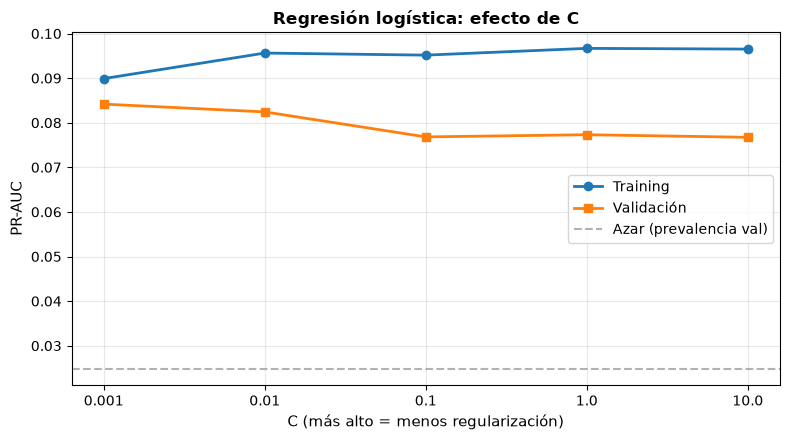


**Qué vimos:**
- El mejor valor según validación fue **C = 0.001**, con PR-AUC de 0.084 en validación y 0.090 en train: train y validación quedan parecidos, así que **no vemos sobreajuste fuerte**.
- Para comparar: un modelo al azar tendría un PR-AUC de ≈ 0.025 en validación.


In [10]:
valores_C = [0.001, 0.01, 0.1, 1, 10]
tabla_lr, pipes_lr = ajustar_y_comparar(
    valores_C,
    lambda C: LogisticRegression(C=C, class_weight="balanced", max_iter=2000, random_state=SEED),
    escalar=True)
display(tabla_lr)

graficar_tuning(tabla_lr, "Regresión logística: efecto de C", "C (más alto = menos regularización)", "02_tuning_regresion_logistica.png")
mejor_C = resumen_tuning(tabla_lr, "C")
modelo_lr = pipes_lr[mejor_C]

## 8. Árbol de decisión

El árbol hace preguntas sucesivas sobre las variables (por ejemplo, "¿tiene sanción previa?") y termina en una hoja con una predicción. Es muy fácil de explicar, pero si crece demasiado **memoriza** el entrenamiento.

Controlamos su complejidad con **max_depth** (profundidad máxima) y exigimos al menos 20 proveedores por hoja (`min_samples_leaf=20`). También usamos `class_weight="balanced"`. No estandarizamos las variables para este modelo.

,valor,PR-AUC train,PR-AUC val
0,2,0.045,0.049
1,3,0.061,0.059
2,4,0.080,0.063
3,5,0.099,0.064
4,7,0.149,0.056
5,10,0.204,0.051
6,15,0.298,0.058


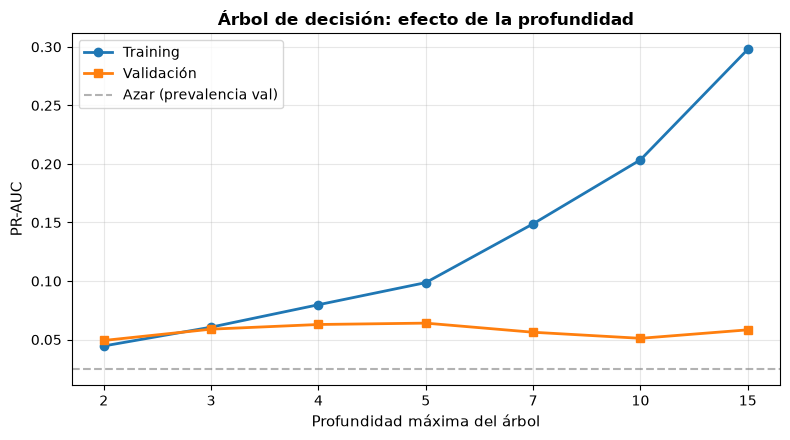


**Qué vimos:**
- El mejor valor según validación fue **max_depth = 5**, con PR-AUC de 0.064 en validación y 0.099 en train: train y validación quedan parecidos, así que **no vemos sobreajuste fuerte**.
- Para comparar: un modelo al azar tendría un PR-AUC de ≈ 0.025 en validación.


In [11]:
profundidades = [2, 3, 4, 5, 7, 10, 15]
tabla_arbol, pipes_arbol = ajustar_y_comparar(
    profundidades,
    lambda d: DecisionTreeClassifier(max_depth=d, min_samples_leaf=20, class_weight="balanced", random_state=SEED),
    escalar=False)
display(tabla_arbol)

graficar_tuning(tabla_arbol, "Árbol de decisión: efecto de la profundidad", "Profundidad máxima del árbol", "03_tuning_arbol.png")
mejor_prof = resumen_tuning(tabla_arbol, "max_depth")
modelo_arbol = pipes_arbol[mejor_prof]

## 9. Qué variables pesan y qué casos detectamos

Miramos dos cosas para entender mejor los resultados:
1. **Qué variables usan más los dos modelos interpretables** (regresión logística y árbol).
2. **Si el mejor modelo solo detecta a quienes ya tenían sanciones** (reincidentes) o también a proveedores "nuevos" en el sistema de sanciones.

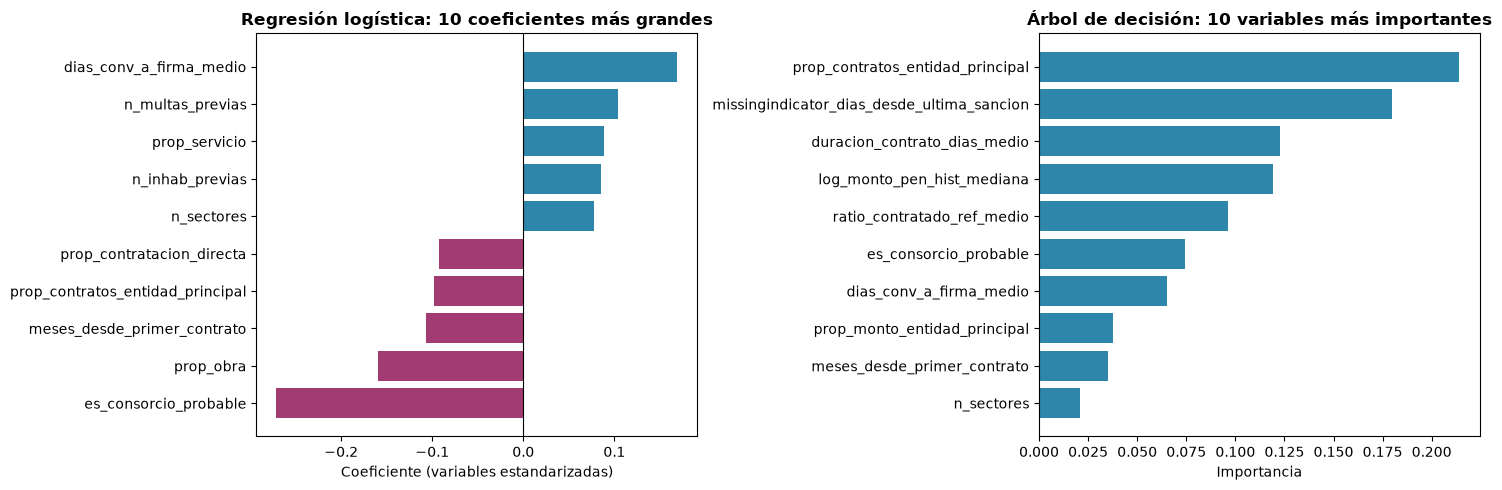


**Cómo leerlo:** en la regresión logística, un coeficiente positivo (azul) sube la probabilidad de sanción y uno negativo (morado) la baja. En el árbol, la importancia indica cuánto contribuye cada variable a separar sancionados de no sancionados.

**Qué vimos:**
- En la regresión logística, las variables que más **aumentan** el riesgo son `dias_conv_a_firma_medio`, `n_multas_previas`, `prop_servicio`, y las que más lo **reducen** son `es_consorcio_probable`, `prop_obra`, `meses_desde_primer_contrato`.
- El árbol se apoya sobre todo en `prop_contratos_entidad_principal`, `missingindicator_dias_desde_ultima_sancion`, `duracion_contrato_dias_medio`.
- Las columnas que empiezan con `missingindicator_` son los indicadores de "dato vacío" que agregamos al preprocesar; si aparecen arriba, el hecho de que el dato falte ya es informativo.


In [13]:
nombres = modelo_lr.named_steps["prep"].named_steps["imputador"].get_feature_names_out(FEATURES)

coef = pd.Series(modelo_lr.named_steps["modelo"].coef_[0], index=nombres)
top_lr = coef.reindex(coef.abs().sort_values(ascending=False).head(10).index).sort_values()

imp_arbol = pd.Series(modelo_arbol.named_steps["modelo"].feature_importances_, index=nombres)
top_arbol = imp_arbol.sort_values(ascending=False).head(10).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].barh(top_lr.index, top_lr.values, color=[color_accent2 if v < 0 else color_accent1 for v in top_lr.values])
ax[0].axvline(0, color="k", linewidth=0.8)
ax[0].set_title("Regresión logística: 10 coeficientes más grandes", fontsize=12, fontweight="bold")
ax[0].set_xlabel("Coeficiente (variables estandarizadas)")

ax[1].barh(top_arbol.index, top_arbol.values, color=color_accent1)
ax[1].set_title("Árbol de decisión: 10 variables más importantes", fontsize=12, fontweight="bold")
ax[1].set_xlabel("Importancia")

plt.tight_layout()
guardar_grafico("08_importancia_variables.png")
plt.show()

positivas = ", ".join(f"`{n}`" for n in top_lr[top_lr > 0].index[::-1][:3])
negativas = ", ".join(f"`{n}`" for n in top_lr[top_lr < 0].index[:3])
principales_arbol = ", ".join(f"`{n}`" for n in top_arbol.index[::-1][:3])
mostrar(f"""
**Cómo leerlo:** en la regresión logística, un coeficiente positivo (azul) sube la probabilidad de sanción y uno negativo (morado) la baja. En el árbol, la importancia indica cuánto contribuye cada variable a separar sancionados de no sancionados.

**Qué vimos:**
- En la regresión logística, las variables que más **aumentan** el riesgo son {positivas if positivas else '(ninguna positiva en el top 10)'}, y las que más lo **reducen** son {negativas if negativas else '(ninguna negativa en el top 10)'}.
- El árbol se apoya sobre todo en {principales_arbol}.
- Las columnas que empiezan con `missingindicator_` son los indicadores de "dato vacío" que agregamos al preprocesar; si aparecen arriba, el hecho de que el dato falte ya es informativo.
""")

## 10. Conclusiones y próximos pasos

- **Pocos positivos:** cada corte tiene decenas o pocos cientos de sancionados, así que las métricas tienen bastante incertidumbre. Una sola partición de prueba no basta para afirmar que un modelo es claramente mejor que otro cuando las diferencias son pequeñas.
- **Validación reutilizada:** el corte de validación sirve para elegir hiperparámetros y fijar el umbral, así que sus métricas son algo optimistas; por eso el número que importa es el de prueba.
- **Un solo corte de validación y uno de prueba:** los resultados dependen de cómo estuvo ese semestre en particular.
- **Proveedores repetidos:** un mismo proveedor aparece en varios cortes, por lo que train y prueba comparten proveedores (aunque en fechas distintas).
- **Etiqueta incompleta:** "no sancionado" solo significa que no vemos una sanción en las bases oficiales durante los 12 meses; no quiere decir que el proveedor no haya incumplido. Además, las sanciones anteriores a 2021 están incompletas.
- **Consorcios:** para los consorcios probables usamos el RUC de pago como identificador, lo cual es una inferencia.
- **Probabilidades:** por usar pesos de clase, las probabilidades no están calibradas; sirven para ordenar proveedores, no para leerlas como "% real de riesgo".

**Importante:** el modelo es un score para **priorizar revisiones**. Un riesgo alto no demuestra fraude, corrupción ni responsabilidad del proveedor.

**Siguientes pasos (entregable final):**
- Implementar y evaluar **KNN** y **MLP** con la misma metodología.
- Pasar las funciones de preparación, modelos y evaluación a `src/` (`preprocessing.py`, `models.py`, `evaluation.py`).
- Completar la tabla comparativa (`results/metrics.csv`) y el análisis de por qué un modelo funcionó mejor.
- Evaluar con más cortes temporales y ajustar pesos de clase o umbrales según la capacidad real de revisión.